# Kernel PCA / تحليل المكوّنات الرئيسية بالنواة

Generate two concentric rings. Fit the same classifier on the original features and on two kernel PCA coordinates, then compare their test scores. Run the cells in order with **Shift + Enter**.

أنشئ حلقتين لهما المركز نفسه. درّب المصنّف نفسه على السمات الأصلية ثمّ على إحداثيَين من تحليل المكوّنات بالنواة، وقارن دقّة الاختبار. شغّل الخلايا بالترتيب باستخدام **Shift + Enter**.

## Fit and check / درّب واختبر

The training split fits the scaler, the projection and logistic regression. The test split measures how often the pipeline predicts the correct class.

يستخدم خط المعالجة بيانات التدريب لضبط المقاييس وحساب الإسقاط وتدريب الانحدار اللوجستي. وتقيس بيانات الاختبار كم مرّة يتوقّع الخط الفئة الصحيحة.

In [1]:
from sklearn.datasets import make_circles
from sklearn.decomposition import KernelPCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X, y = make_circles(n_samples=400, factor=0.3, noise=0.03, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
model = Pipeline([
    ("scale", StandardScaler()),
    ("reduce", KernelPCA(n_components=2, kernel="rbf", gamma=2)),
    ("classify", LogisticRegression(max_iter=1000)),
])
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print(f"Test accuracy after reduction: {accuracy_score(y_test, predictions):.1%}")
print("Confusion matrix (rows = true, columns = predicted):")
print(confusion_matrix(y_test, predictions, labels=model.classes_))

original_model = Pipeline([
    ("scale", StandardScaler()),
    ("classify", LogisticRegression(max_iter=1000)),
])
original_model.fit(X_train, y_train)
print(f"Test accuracy on original features: {original_model.score(X_test, y_test):.1%}")

Test accuracy after reduction: 100.0%
Confusion matrix (rows = true, columns = predicted):
[[50  0]
 [ 0 50]]
Test accuracy on original features: 55.0%


## See it / شاهد النتيجة

Compare the two straight boundaries. The points in the two panels are the same held-out samples, shown in different coordinates. The shading shows the classifier's predicted class at each position.

قارن بين الحدّين المستقيمين. يعرض الرسمان عينات الاختبار نفسها بإحداثيات مختلفة. يوضّح لون الخلفية الفئة التي يتوقّعها المصنّف في كل موضع.

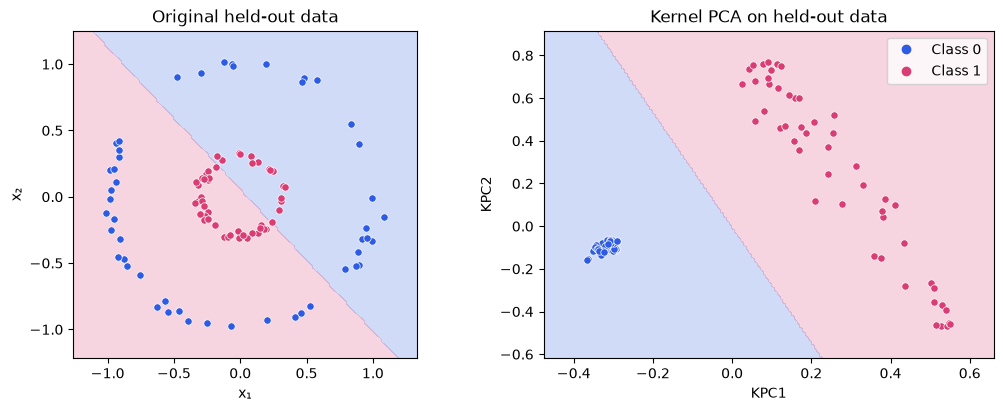

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

colors = ["#2d5be3", "#d93d74", "#287f60"]
classes = model.classes_
region_colors = ListedColormap(colors[:len(classes)])
legend = [
    Line2D([], [], marker="o", linestyle="none", color=colors[i], label=f"Class {name}")
    for i, name in enumerate(classes)
]

def draw_regions(ax, data, labels, classifier, title, x_label, y_label):
    lo, hi = data.min(axis=0), data.max(axis=0)
    padding = np.maximum((hi - lo) * 0.12, 0.05)
    x = np.linspace(lo[0] - padding[0], hi[0] + padding[0], 160)
    y = np.linspace(lo[1] - padding[1], hi[1] + padding[1], 160)
    xx, yy = np.meshgrid(x, y)
    grid = np.column_stack((xx.ravel(), yy.ravel()))
    regions = np.searchsorted(classes, classifier.predict(grid)).reshape(xx.shape)
    ax.contourf(xx, yy, regions, levels=np.arange(len(classes) + 1) - 0.5,
                cmap=region_colors, alpha=0.22)
    for i, name in enumerate(classes):
        points = data[labels == name]
        ax.scatter(points[:, 0], points[:, 1], color=colors[i],
                   edgecolor="white", linewidth=0.5, s=28)
    ax.set(title=title, xlabel=x_label, ylabel=y_label)

projected = model[:-1].transform(X_test)
logistic = model.named_steps["classify"]

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
draw_regions(left, X_test, y_test, original_model, "Original held-out data", "x₁", "x₂")
draw_regions(right, projected, y_test, logistic, "Kernel PCA on held-out data", "KPC1", "KPC2")
left.set_aspect("equal")
right.legend(handles=legend)
plt.show()